# UrbanHub — Partie 1 : flux batch, analyse météorologique

Données : NOAA Global Hourly, stations situées en France, 5 dernières années.
Pré-requis : avoir lancé `python -m src.batch_noaa.download` puis `python -m src.batch_noaa.clean` depuis la racine du repo.

In [1]:
# ── Imports ──
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import IsolationForest

from src.batch_noaa import config
from src.batch_noaa.clean import daily_precipitation, local_date

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 4)
FIG_DIR = ROOT / "reports" / "figures" / "partie1"
FIG_DIR.mkdir(parents=True, exist_ok=True)

In [2]:
# ── Chargement des données nettoyées ──
cols = ["station_id", "station_name", "city", "latitude", "longitude", "timestamp",
        "temperature", "dew_point", "wind_speed", "wind_direction", "pressure",
        "visibility", "precipitation", "precipitation_period_h"]
df = pd.read_parquet(config.PROCESSED_DIR, columns=cols)
df["date"] = local_date(df["timestamp"])

print(f"{len(df):,} observations horaires, {df['station_id'].nunique()} stations")
print("période :", df["timestamp"].min(), "->", df["timestamp"].max())
df.describe().round(1)

958,828 observations horaires, 12 stations
période : 2021-01-01 00:00:00+00:00 -> 2025-08-24 21:30:00+00:00


,latitude,longitude,temperature,dew_point,wind_speed,wind_direction,pressure,visibility,precipitation,precipitation_period_h,date
count,958828.0,958828.0,950619.0,951860.0,958544.0,772097.0,958404.0,958754.0,413763.0,414927.0,958828
mean,46.4,2.9,14.3,8.9,3.8,200.9,1016.8,9.5,0.1,1.7,2023-04-25 23:57:10.593182
min,43.4,-1.7,-13.0,-15.0,0.0,10.0,968.0,0.0,0.0,1.0,2021-01-01 00:00:00
25%,43.6,1.4,9.0,5.0,2.1,130.0,1012.0,9.9,0.0,1.0,2022-02-26 00:00:00
50%,45.7,2.6,14.0,9.0,3.1,210.0,1017.0,9.9,0.0,1.0,2023-04-22 00:00:00
75%,48.7,5.2,20.0,13.0,5.1,290.0,1022.0,10.0,0.0,3.0,2024-06-23 00:00:00
max,50.6,7.6,42.0,27.0,23.2,360.0,1044.0,70.0,99.0,3.0,2025-08-24 00:00:00
std,2.5,3.0,7.6,5.9,2.4,103.0,8.3,2.1,0.9,0.9,NaN


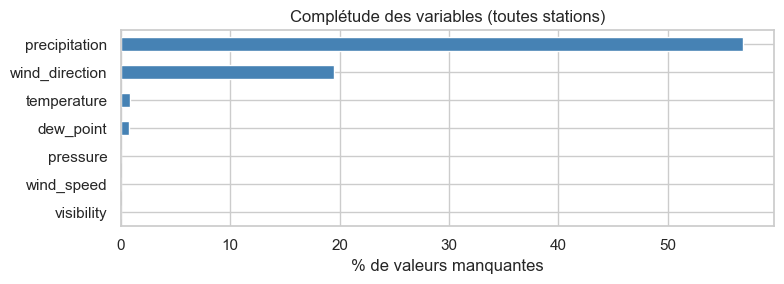

In [3]:
# ── Qualité : taux de valeurs manquantes après nettoyage ──
vars_ = ["temperature", "dew_point", "wind_speed", "wind_direction", "pressure", "visibility", "precipitation"]
missing = df[vars_].isna().mean().mul(100).sort_values()
ax = missing.plot.barh(color="steelblue", figsize=(8, 3))
ax.set_xlabel("% de valeurs manquantes")
ax.set_title("Complétude des variables (toutes stations)")
plt.tight_layout(); plt.savefig(FIG_DIR / "00_completude.png", dpi=120); plt.show()

La pluie est très incomplète au niveau horaire : elle n'est déclarée que dans certains messages (SYNOP), en cumul sur 1h, 3h, 6h, 12h ou 24h selon la station. On la reconstruit donc en cumul journalier (`daily_precipitation`).

In [4]:
# ── Agrégation journalière par station ──
daily = (df.groupby(["station_id", "date"])
           .agg(t_mean=("temperature", "mean"), t_min=("temperature", "min"),
                t_max=("temperature", "max"), wind_mean=("wind_speed", "mean"),
                wind_max=("wind_speed", "max"), p_mean=("pressure", "mean"),
                p_min=("pressure", "min"), vis_mean=("visibility", "mean"),
                vis_min=("visibility", "min"), n_obs=("temperature", "count"))
           .reset_index())
daily = daily[daily["n_obs"] >= 16]          # au moins 16 heures de mesures dans la journée
daily = daily.merge(daily_precipitation(df), on=["station_id", "date"], how="left")
daily["city"] = daily["station_id"].map(config.CITY_STATIONS)
print(f"{len(daily):,} journées-station exploitables")
daily.head()

20,157 journées-station exploitables


,station_id,date,t_mean,t_min,t_max,wind_mean,wind_max,p_mean,p_min,vis_mean,vis_min,n_obs,precipitation_day,city
0,07015099999,2021-01-01,1.152174,-1.0,4.0,2.395652,4.1,1009.739130,1007.0,9.119457,6.0,46,0.4,Lille
1,07015099999,2021-01-02,1.187500,-2.0,4.0,1.162500,2.1,1013.395833,1013.0,4.941667,0.5,48,0.4,Lille
2,07015099999,2021-01-03,2.895833,2.0,4.0,2.964583,5.7,1014.770833,1014.0,5.363208,0.4,48,0.4,Lille
3,07015099999,2021-01-04,2.604167,2.0,3.0,4.945833,6.2,1015.000000,1014.0,9.686708,7.0,48,1.0,Lille
4,07015099999,2021-01-05,2.687500,2.0,3.0,4.500000,6.2,1015.666667,1015.0,9.749208,8.0,48,0.0,Lille


## Q1 — Peut-on identifier des périodes météorologiques anormales ?

Méthode : pour chaque station, on calcule une « normale » de température journalière : médiane et écart-type robuste (IQR) de toutes les valeurs observées à ±15 jours de la même date, sur les 5 ans. La médiane évite qu'une canicule ou une vague de froid déforme la normale. L'écart à cette normale, en nombre d'écarts-types (z-score), est ensuite moyenné sur toute la France. Une période anormale = au moins 3 jours consécutifs avec |z| ≥ 1.5.

In [5]:
# ── Normales saisonnières par station (robustes aux événements extrêmes) ──
daily["doy"] = daily["date"].dt.dayofyear.clip(upper=365)
W = 15   # fenêtre de ±15 jours autour de chaque jour de l'année

clims = []
for st, g in daily.groupby("station_id"):
    piv = g.pivot_table(index="doy", columns=g["date"].dt.year, values="t_mean").reindex(range(1, 366))
    if piv.notna().sum().sum() < 300:      # pas assez d'historique pour une normale fiable
        continue
    arr = piv.to_numpy()
    ext = np.vstack([arr[-W:], arr, arr[:W]])                         # année circulaire
    win = np.stack([ext[i:i + 2 * W + 1].ravel() for i in range(365)])  # toutes les valeurs de la fenêtre
    q25, med, q75 = np.nanpercentile(win, [25, 50, 75], axis=1)
    # médiane et écart-type robuste (IQR) : une canicule ne déforme pas la normale
    clims.append(pd.DataFrame({"station_id": st, "doy": range(1, 366),
                               "clim_mean": med, "clim_std": np.maximum((q75 - q25) / 1.349, 0.5)}))
clim = pd.concat(clims)
daily = daily.merge(clim, on=["station_id", "doy"], how="left")
daily["t_anom"] = daily["t_mean"] - daily["clim_mean"]
daily["t_z"] = daily["t_anom"] / daily["clim_std"]

In [6]:
# ── Indice national et détection des périodes ──
nat = daily.groupby("date").agg(t_z=("t_z", "mean"), t_anom=("t_anom", "mean"),
                                n_stations=("station_id", "nunique"))
nat["flag"] = np.sign(nat["t_z"]).where(nat["t_z"].abs() >= 1.5, 0)

# regroupe les jours consécutifs de même signe
run_id = (nat["flag"] != nat["flag"].shift()).cumsum()
periods = (nat[nat["flag"] != 0].groupby(run_id[nat["flag"] != 0])
             .agg(debut=("t_z", lambda s: s.index.min()), fin=("t_z", lambda s: s.index.max()),
                  jours=("t_z", "size"), z_max=("t_z", lambda s: s.abs().max()),
                  ecart_moyen_C=("t_anom", "mean")))
periods = periods[periods["jours"] >= 3].copy()
periods["type"] = np.where(periods["ecart_moyen_C"] > 0, "chaud", "froid")
periods = periods.sort_values("z_max", ascending=False).reset_index(drop=True)
periods.round(2)

,debut,fin,jours,z_max,ecart_moyen_C,type
0,2022-07-17,2022-07-19,3,2.70,5.82,chaud
1,2025-06-29,2025-07-01,3,2.39,6.47,chaud
2,2022-04-01,2022-04-04,4,2.35,-6.42,froid
3,2021-02-10,2021-02-14,3,2.16,-6.14,froid
4,2022-05-15,2022-05-19,5,2.08,5.26,chaud
5,2023-02-26,2023-03-02,5,2.06,-4.95,froid
6,2022-12-11,2022-12-13,3,2.05,-6.14,froid
7,2025-04-30,2025-05-03,4,2.02,5.32,chaud
8,2024-04-22,2024-04-24,3,1.73,-4.79,froid


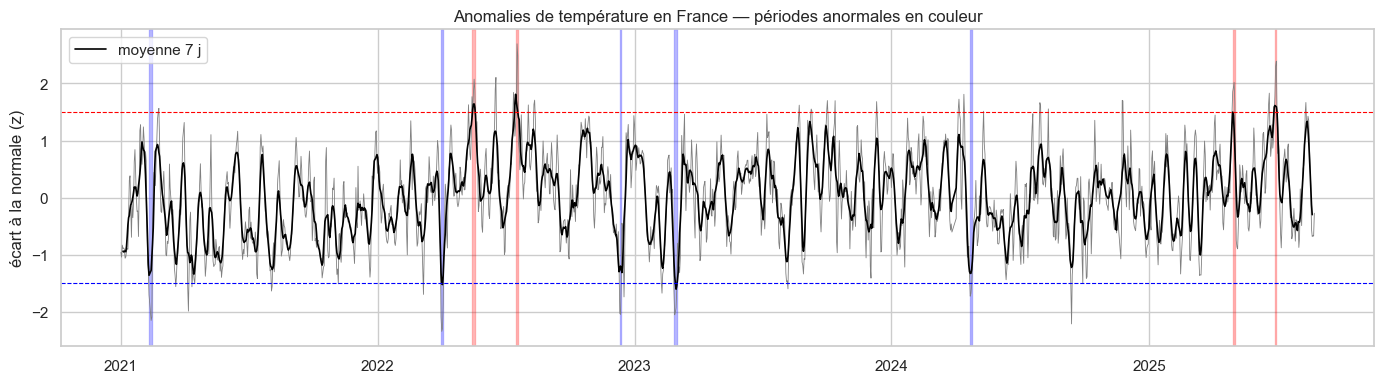

In [7]:
# ── Visualisation ──
fig, ax = plt.subplots(figsize=(14, 4))
x = nat.index.to_numpy()   # tableaux numpy : compatibilité anciennes versions de matplotlib
ax.plot(x, nat["t_z"].to_numpy(), lw=0.6, color="grey")
ax.plot(x, nat["t_z"].rolling(7, center=True).mean().to_numpy(), lw=1.2, color="black", label="moyenne 7 j")
for _, r in periods.iterrows():
    ax.axvspan(r["debut"], r["fin"], color="red" if r["type"] == "chaud" else "blue", alpha=0.25)
ax.axhline(1.5, ls="--", c="red", lw=0.8); ax.axhline(-1.5, ls="--", c="blue", lw=0.8)
ax.set_ylabel("écart à la normale (z)")
ax.set_title("Anomalies de température en France — périodes anormales en couleur")
ax.legend(); plt.tight_layout(); plt.savefig(FIG_DIR / "q1_anomalies_temperature.png", dpi=120); plt.show()

Complément multivariable : une Isolation Forest repère les journées atypiques en combinant température, vent, pression, pluie et visibilité (et pas seulement la température).

In [8]:
# ── Isolation Forest sur les journées nationales ──
feat = daily.groupby("date").agg(t_z=("t_z", "mean"), wind_max=("wind_max", "mean"),
                                 p_min=("p_min", "mean"), precip=("precipitation_day", "mean"),
                                 vis_min=("vis_min", "mean")).dropna()
iso = IsolationForest(contamination=0.02, random_state=0).fit(feat)
feat["score"] = -iso.score_samples(feat)
feat["anomalie"] = iso.predict(feat[["t_z", "wind_max", "p_min", "precip", "vis_min"]]) == -1
print(f"{feat['anomalie'].sum()} journées atypiques sur {len(feat)}")
feat.sort_values("score", ascending=False).head(15).round(2)

29 journées atypiques sur 1448


,t_z,wind_max,p_min,precip,vis_min,score,anomalie
date,,,,,,,
2023-10-20,0.52,9.65,979.42,13.43,3.46,0.68,True
2023-11-02,-0.25,12.91,984.38,8.82,5.82,0.68,True
2024-02-10,0.52,9.70,983.75,15.88,3.78,0.68,True
2024-02-22,1.01,13.55,992.97,7.72,4.90,0.66,True
2021-10-03,0.36,9.93,1000.58,25.25,3.16,0.66,True
2023-11-04,-0.43,10.47,979.83,9.40,4.68,0.66,True
2024-10-09,0.10,9.88,988.08,20.68,5.88,0.65,True
2024-01-17,0.31,7.68,989.42,11.40,2.79,0.65,True
2024-02-26,0.10,9.40,993.08,17.16,5.86,0.62,True


## Q2 — Existe-t-il une corrélation entre conditions météo et visibilité ?

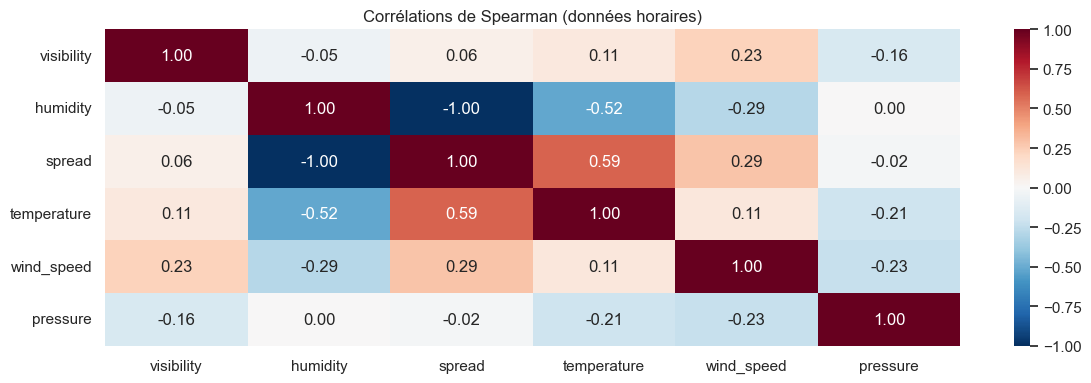

In [9]:
# ── Humidité relative (formule de Magnus) et écart température / point de rosée ──
def rel_humidity(t, td):
    return 100 * np.exp(17.625 * td / (243.04 + td)) / np.exp(17.625 * t / (243.04 + t))

h = df.dropna(subset=["visibility", "temperature", "dew_point"]).copy()
if len(h) > 2_000_000:
    h = h.sample(2_000_000, random_state=0)
h["humidity"] = rel_humidity(h["temperature"], h["dew_point"])
h["spread"] = h["temperature"] - h["dew_point"]

corr = h[["visibility", "humidity", "spread", "temperature", "wind_speed", "pressure"]].corr(method="spearman")
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1)
plt.title("Corrélations de Spearman (données horaires)")
plt.tight_layout(); plt.savefig(FIG_DIR / "q2_correlations.png", dpi=120); plt.show()

c:\Users\Steven\AppData\Local\Programs\Python\Python39\lib\site-packages\seaborn\categorical.py:641: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped_vals = vals.groupby(grouper)
c:\Users\Steven\AppData\Local\Programs\Python\Python39\lib\site-packages\seaborn\categorical.py:641: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped_vals = vals.groupby(grouper)


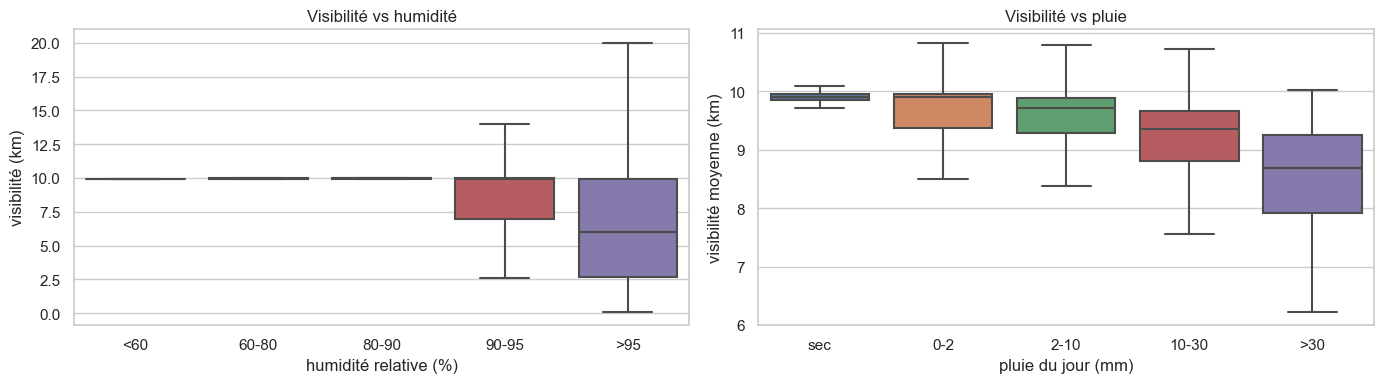

In [10]:
# ── Visibilité selon l'humidité et selon la pluie du jour ──
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

h["classe_humidite"] = pd.cut(h["humidity"], [0, 60, 80, 90, 95, 100.1],
                              labels=["<60", "60-80", "80-90", "90-95", ">95"])
sns.boxplot(data=h, x="classe_humidite", y="visibility", showfliers=False, ax=axes[0])
axes[0].set(xlabel="humidité relative (%)", ylabel="visibilité (km)", title="Visibilité vs humidité")

d = daily.dropna(subset=["precipitation_day", "vis_mean"]).copy()
d["classe_pluie"] = pd.cut(d["precipitation_day"], [-0.1, 0.1, 2, 10, 30, 1000],
                           labels=["sec", "0-2", "2-10", "10-30", ">30"])
sns.boxplot(data=d, x="classe_pluie", y="vis_mean", showfliers=False, ax=axes[1])
axes[1].set(xlabel="pluie du jour (mm)", ylabel="visibilité moyenne (km)", title="Visibilité vs pluie")
plt.tight_layout(); plt.savefig(FIG_DIR / "q2_visibilite_humidite_pluie.png", dpi=120); plt.show()

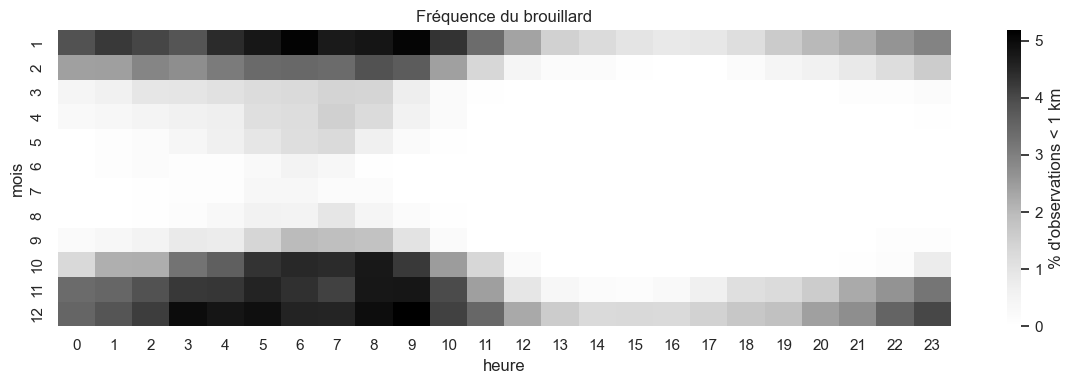

In [11]:
# ── Fréquence du brouillard (visibilité < 1 km) par mois et par heure locale ──
h["mois"] = h["timestamp"].dt.tz_convert("Europe/Paris").dt.month
h["heure"] = h["timestamp"].dt.tz_convert("Europe/Paris").dt.hour
fog = h.assign(brouillard=h["visibility"] < 1).pivot_table(index="mois", columns="heure",
                                                           values="brouillard", aggfunc="mean") * 100
sns.heatmap(fog, cmap="Greys", cbar_kws={"label": "% d'observations < 1 km"})
plt.title("Fréquence du brouillard"); plt.tight_layout()
plt.savefig(FIG_DIR / "q2_brouillard_mois_heure.png", dpi=120); plt.show()

## Q3 — Évolution saisonnière de la température en France et dans les principales villes

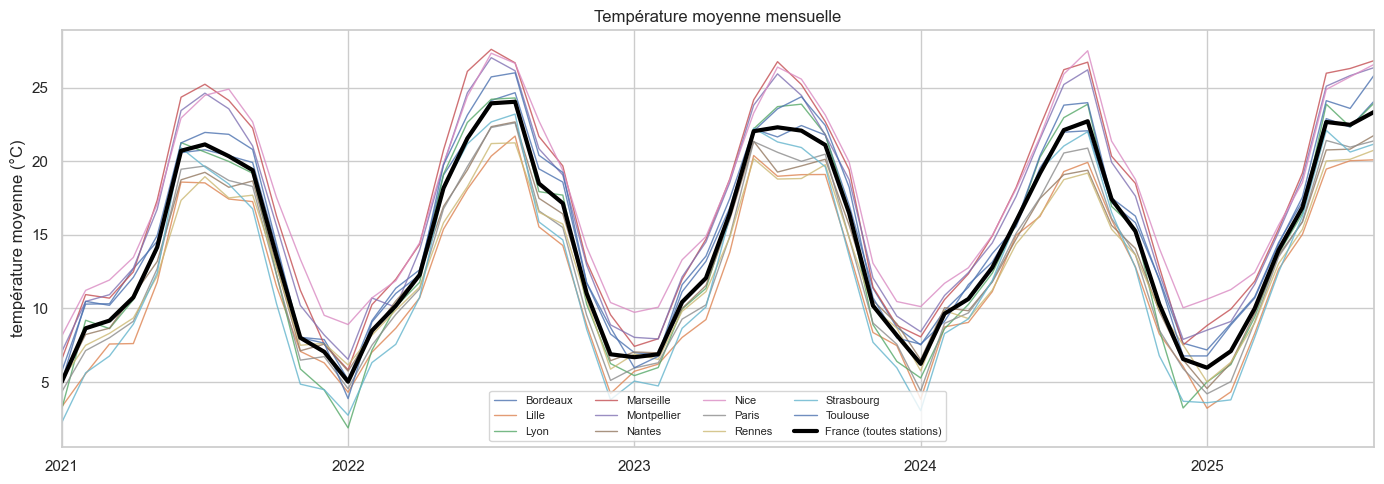

In [12]:
# ── Moyennes mensuelles ──
m = df.dropna(subset=["temperature"]).copy()
m["mois"] = m["date"].values.astype("datetime64[M]")

france = m.groupby("mois")["temperature"].mean()
villes = m[m["city"].notna()].groupby(["mois", "city"])["temperature"].mean().unstack()

fig, ax = plt.subplots(figsize=(14, 5))
villes.plot(ax=ax, lw=1, alpha=0.8)
france.plot(ax=ax, lw=3, color="black", label="France (toutes stations)")
ax.set(ylabel="température moyenne (°C)", xlabel="", title="Température moyenne mensuelle")
ax.legend(ncol=4, fontsize=8)
plt.tight_layout(); plt.savefig(FIG_DIR / "q3_temperature_mensuelle.png", dpi=120); plt.show()

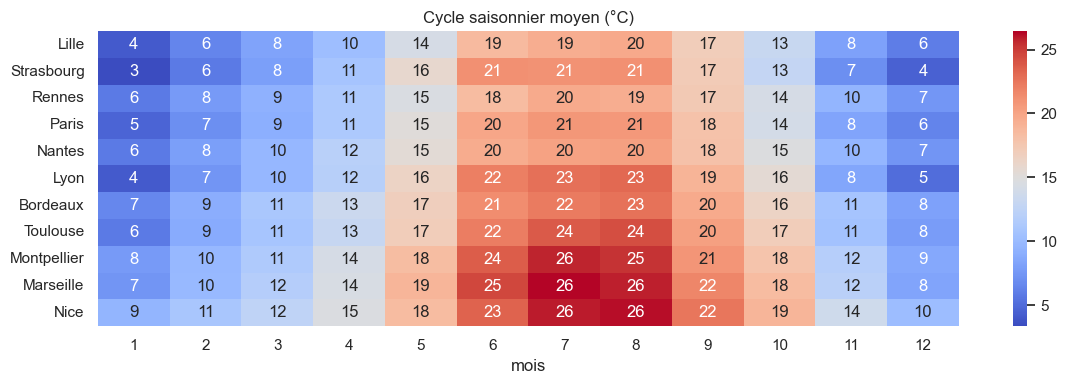

amplitude saisonnière (mois le plus chaud - mois le plus froid, °C) :
city
Rennes         13.8
Nantes         14.5
Lille          15.6
Paris          16.1
Bordeaux       16.1
Nice           16.7
Strasbourg     17.8
Montpellier    18.0
Toulouse       18.5
Lyon           19.0
Marseille      19.1


In [13]:
# ── Cycle saisonnier moyen par ville (heatmap ville x mois) ──
m["num_mois"] = m["date"].dt.month
cycle = m[m["city"].notna()].pivot_table(index="city", columns="num_mois",
                                         values="temperature", aggfunc="mean")
cycle = cycle.loc[cycle.mean(axis=1).sort_values().index]
sns.heatmap(cycle, annot=True, fmt=".0f", cmap="coolwarm")
plt.title("Cycle saisonnier moyen (°C)"); plt.xlabel("mois"); plt.ylabel("")
plt.tight_layout(); plt.savefig(FIG_DIR / "q3_cycle_saisonnier_villes.png", dpi=120); plt.show()

amplitude = (cycle.max(axis=1) - cycle.min(axis=1)).sort_values()
print("amplitude saisonnière (mois le plus chaud - mois le plus froid, °C) :")
print(amplitude.round(1).to_string())

In [14]:
# ── Tendance par saison et par année (France) ──
saison = {12: "hiver", 1: "hiver", 2: "hiver", 3: "printemps", 4: "printemps", 5: "printemps",
          6: "été", 7: "été", 8: "été", 9: "automne", 10: "automne", 11: "automne"}
m["saison"] = m["num_mois"].map(saison)
m["annee_saison"] = m["date"].dt.year + (m["num_mois"] == 12)   # décembre compté avec l'hiver suivant
s = m.pivot_table(index="annee_saison", columns="saison", values="temperature", aggfunc="mean")
s[["hiver", "printemps", "été", "automne"]].round(1)

saison,hiver,printemps,été,automne
annee_saison,,,,
2021,6.6,11.3,20.7,13.6
2022,6.8,13.6,23.2,15.5
2023,6.8,13.0,22.1,15.9
2024,8.0,13.2,21.3,14.5
2025,6.5,13.6,22.8,NaN


## Q4 — Quels sont les jours présentant des conditions météorologiques extrêmes ?

Deux approches :
- **seuils absolus** inspirés de la vigilance Météo-France : Tmax ≥ 35 °C, Tmin ≤ -10 °C, vent moyen horaire ≥ 15 m/s (54 km/h), pluie ≥ 50 mm/jour, brouillard dense (visibilité < 200 m) ;
- **seuils relatifs** à chaque station (percentiles 99 / 1), pour tenir compte du climat local (35 °C n'a pas le même sens à Brest et à Nîmes).

In [15]:
# ── Seuils absolus ──
crit = {
    "canicule": daily["t_max"] >= 35,
    "grand_froid": daily["t_min"] <= -10,
    "vent_fort": daily["wind_max"] >= 15,
    "fortes_pluies": daily["precipitation_day"] >= 50,
    "brouillard_dense": daily["vis_min"] < 0.2,
}
for k, v in crit.items():
    daily[k] = v.fillna(False)
types = list(crit)

par_jour = daily.groupby("date")[types].sum()
par_jour["stations_touchees"] = daily.assign(x=daily[types].any(axis=1)).groupby("date")["x"].sum()
par_jour["part_stations_%"] = 100 * par_jour["stations_touchees"] / daily.groupby("date")["station_id"].nunique()
top = par_jour.sort_values("part_stations_%", ascending=False).head(20)
top.round(1)

,canicule,grand_froid,vent_fort,fortes_pluies,brouillard_dense,stations_touchees,part_stations_%
date,,,,,,,
2022-07-18,10,0,0,0,0,10,83.3
2025-06-30,9,0,0,0,0,9,75.0
2025-07-01,9,0,0,0,0,9,75.0
2022-06-18,9,0,0,0,0,9,75.0
2025-08-12,7,0,0,0,0,7,58.3
2022-07-19,7,0,0,0,0,7,58.3
2022-08-03,7,0,0,0,0,7,58.3
2025-08-15,7,0,0,0,0,7,58.3
2023-08-23,6,0,0,0,0,6,50.0


In [16]:
# ── Seuils relatifs (percentiles par station) ──
q = daily.groupby("station_id").agg(tmax99=("t_max", lambda s: s.quantile(0.99)),
                                    tmin01=("t_min", lambda s: s.quantile(0.01)),
                                    wind99=("wind_max", lambda s: s.quantile(0.99)),
                                    rain99=("precipitation_day", lambda s: s.quantile(0.99)))
d = daily.merge(q, on="station_id")
d["score_extreme"] = ((d["t_max"] >= d["tmax99"]).astype(int) + (d["t_min"] <= d["tmin01"]).astype(int)
                      + (d["wind_max"] >= d["wind99"]).astype(int)
                      + (d["precipitation_day"] >= d["rain99"]).astype(int))
rel = d.groupby("date")["score_extreme"].mean().sort_values(ascending=False)
print("journées les plus extrêmes relativement aux climats locaux :")
rel.head(15).round(3)

journées les plus extrêmes relativement aux climats locaux :


date
2024-02-22    0.917
2025-01-14    0.917
2025-06-30    0.833
2022-06-18    0.750
2024-01-20    0.667
2022-08-03    0.667
2022-07-18    0.667
2022-06-17    0.667
2025-08-12    0.667
2025-08-13    0.667
2022-12-17    0.583
2022-12-12    0.583
2025-01-15    0.583
2023-03-10    0.583
2022-04-08    0.583
Name: score_extreme, dtype: float64

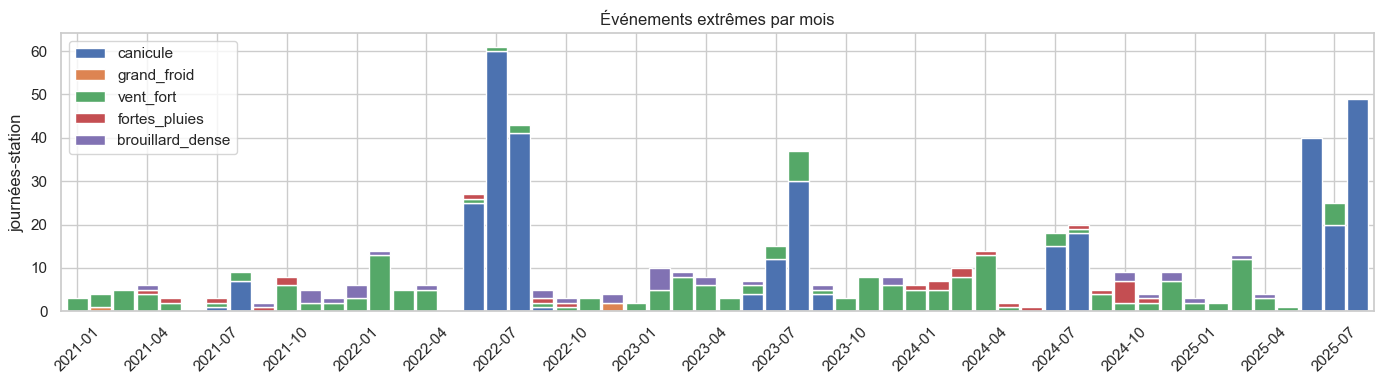

In [17]:
# ── Nombre de journées-station extrêmes par mois et par type ──
mensuel = daily.groupby(daily["date"].values.astype("datetime64[M]"))[types].sum()
mensuel.index = pd.to_datetime(mensuel.index).strftime("%Y-%m")
mensuel.plot.bar(stacked=True, figsize=(14, 4), width=0.9)
plt.xticks(range(0, len(mensuel), 3), mensuel.index[::3], rotation=45)
plt.ylabel("journées-station"); plt.title("Événements extrêmes par mois")
plt.tight_layout(); plt.savefig(FIG_DIR / "q4_extremes_par_mois.png", dpi=120); plt.show()

In [18]:
# ── Export des résultats pour la partie 4 (analyse croisée) ──
out = config.PROCESSED_DIR.parent / "noaa_daily.parquet"
daily.drop(columns=["doy"]).to_parquet(out, index=False)
periods.to_csv(ROOT / "reports" / "partie1_periodes_anormales.csv", index=False)
top.to_csv(ROOT / "reports" / "partie1_jours_extremes.csv")
print("exporté :", out)

exporté : S:\IPSSI\MIA 2e année\DATALAKE\Projet final\urbanhub\data\processed\noaa_daily.parquet


## Interprétation

À rédiger après exécution sur les vraies données :
- **Q1** : quelles périodes ressortent (dates, chaud/froid) ? Correspondent-elles à des événements connus (canicules, vagues de froid) ?
- **Q2** : quelle variable explique le mieux la visibilité ? (attendu : l'humidité / l'écart T-Td, bien plus que le vent ou la pression) ; à quels mois et heures le brouillard est-il le plus fréquent ?
- **Q3** : amplitude saisonnière par ville (climat océanique vs continental vs méditerranéen), années plus chaudes que d'autres ?
- **Q4** : jours les plus extrêmes et type d'événement dominant.